# DSAN 6600 - 04_logisitic_baseline.ipynb

Supporting baseline for Check-in 2: a logisitic regression baseline for ECG diagnositc classification. It is the simple, non-neural comparison model for the CNN in `03_cnn_baseline.ipynb`.

This predicts five diagnositic superclasses from the PTB-XL dataset: NORM, MI, STTC, CD, and HYP. 

The **same split** is used in `03_cnn_baseline.ipynb`: 
| Train on | Validate on | Test on | 
|---| --- | --- | 
| Folds 1-7 | Fold 8 | Folds 9-10|


**Running on Colab (recommended, GPU):**
1. Open this notebook in Colab (File → Open notebook → GitHub → `chloemjones13/6600_final_project`).
2. Runtime → Change runtime type → **T4 GPU**.
3. Runtime → Run all. The setup cells mount Google Drive, clone the repo, build `ptbxl_model.pkl` by running `01_data_cleaning.ipynb`, and download PTB-XL (first session only).
4. After **each** training run, its predictions, history and checkpoint are copied to `MyDrive/6600_project/backup/`. If Colab disconnects, just Run all again: finished runs are restored from Drive and skipped.
5. The last cell zips `results/` and `figures/` for download so they can be committed to the repo.

**Running locally:** run `01_data_cleaning.ipynb` first, and have the PTB-XL 100 Hz files in `data/` (see README for the `wget`). Drive steps are skipped automatically.

**Outputs:** predictions, summary and per-class metrics, qualitative examples, and a config file. 

### Setup (Colab and paths)

In [ ]:
import os
import sys
import glob
import shutil
import subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/chloemjones13/6600_final_project.git"
REPO_DIR = "/content/6600_final_project"

if IN_COLAB:
    !pip install -q wfdb
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/6600_project/"
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR + "/notebooks")
    CACHE_DIR = DRIVE_DIR             # signal cache lives on Drive so it survives sessions
    BACKUP_DIR = DRIVE_DIR + "backup/"
else:
    CACHE_DIR = "../data/"
    BACKUP_DIR = None

PATH = "../data/"                     # ptbxl_model.pkl
SIGNAL_DIR = "../data/"               # folder containing records100/ (Colab: set below)
RESULTS_DIR, CKPT_DIR, FIG_DIR = "../results/", "../checkpoints/", "../figures/"
for d in [RESULTS_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR] + ([BACKUP_DIR] if BACKUP_DIR else []):
    os.makedirs(d, exist_ok=True)

# Build the cleaned modeling data if it's missing (runs notebook 01; needs only the repo CSVs)
if not os.path.exists(PATH + "ptbxl_model.pkl"):
    subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute",
                    "--output", "/tmp/01_executed.ipynb", "01_data_cleaning.ipynb"], check=True)
assert os.path.exists(PATH + "ptbxl_model.pkl"), "01_data_cleaning.ipynb didn't create ptbxl_model.pkl"

print("Colab:", IN_COLAB, "| working dir:", os.getcwd())

**Imports and constants**

In [21]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

TRAIN_GROUPS = ["female", "male", "all"]
SEEDS = [0]
MATCH_SIZE = False
C_VALUES = [0.1, 1.0, 10.0]

### Load the cleaned data and define splits

In [10]:
df = pd.read_pickle(PATH + "ptbxl_model.pkl")
assert (df[CLASSES].sum(axis=1) > 0).all(), "Run the new last cell of 01_data_cleaning.ipynb first"

df["split"] = np.where(df["strat_fold"] <= 7, "train", np.where(df["strat_fold"] == 8, "val", "test"))
print(pd.crosstab(df["split"], df["sex_label"]))

sex_label  female  male
split                  
test         1842  2137
train        6566  7444
val           942  1061


### Load signals

In [ ]:
CACHE = os.path.join(PATH, "X_100hz.npy")
CACHE_IDS = os.path.join(PATH, "X_100hz_ids.npy")


def load_signals(df):
    if os.path.exists(CACHE) and os.path.exists(CACHE_IDS):
        if np.array_equal(np.load(CACHE_IDS), df.index.values):
            return np.load(CACHE)
        print("Cache doesn't match the current data; rebuilding")
    X = np.empty((len(df), 12, 1000), dtype=np.float32)
    for i, filename in enumerate(df["filename_lr"]):
        sig, _ = wfdb.rdsamp(os.path.join(SIGNAL_DIR, filename))
        X[i] = sig.T
        if i % 2000 == 0:
            print(f"{i}/{len(df)}")
    np.save(CACHE, X)
    np.save(CACHE_IDS, df.index.values)
    return X

X = load_signals(df)
print(X.shape)
assert np.isfinite(X).all()

(19992, 12, 1000)


### Feature extraction

In [12]:
def extract_features(X_signals):
    n = X_signals.shape[0]

    features = X_signals.reshape(n, 12, 100, 10).mean(axis = 3)
    return features.reshape(n, 1200).astype(np.float32)

X_features = extract_features(X)
Y = df[CLASSES].to_numpy(dtype=np.int32)

print("Feature matrix:", X_features.shape)
print("Label matrix:", Y.shape)

Feature matrix: (19992, 1200)
Label matrix: (19992, 5)


### Build train / validation / test arrays

In [13]:
split_masks = {
    split: (df["split"] == split).to_numpy()
    for split in ["train", "val", "test"]
}

x_split = {
    split: X_features[split_masks[split]]
    for split in ["train", "val", "test"]
}

y_split = {
    split: Y[split_masks[split]]
    for split in ["train", "val", "test"]
}

meta = {
    split: df.loc[split_masks[split]].copy()
    for split in ["train", "val", "test"]
}

for split in ["train", "val", "test"]:
    print(
        f"{split}: X = {x_split[split].shape}, "
        f"Y = {y_split[split].shape}"
    )

train: X = (14010, 1200), Y = (14010, 5)
val: X = (2003, 1200), Y = (2003, 5)
test: X = (3979, 1200), Y = (3979, 5)


### Training groups by sex

In [14]:
def group_mask(split, group):
    sex = meta[split]["sex"].to_numpy()

    if group == "female":
        return sex == 1
    elif group == "male":
        return sex == 0
    elif group =="all":
        return np.ones(len(sex), dtype = bool)
    else:
        raise ValueError(f"Unknown group: {group}")

print("Training records by group:")
for group in TRAIN_GROUPS:
    print(f"{group}: {group_mask('train', group).sum()}")

print("\nValidation records by group:")
for group in TRAIN_GROUPS:
    print(f"{group}: {group_mask('val', group).sum()}")

Training records by group:
female: 6566
male: 7444
all: 14010

Validation records by group:
female: 942
male: 1061
all: 2003


### Train logisitic regression

In [15]:
def train_logreg(group):
    train_mask = group_mask("train", group)
    val_mask = group_mask("val", group)

    x_train = x_split["train"][train_mask]
    y_train = y_split["train"][train_mask]

    x_val = x_split["val"][val_mask]
    y_val = y_split["val"][val_mask]

    print(f"\nGroup: {group}")
    print(f"Training Records: {len(x_train)}")
    print(f"Validation records: {len(x_val)}")

    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(x_train)
    x_val_scaled = scaler.transform(x_val)

    validation_results = []

    for C in C_VALUES:
        model = OneVsRestClassifier(
            LogisticRegression(C=C, solver = "liblinear", max_iter = 2000, random_state = 0))
        model.fit(x_train_scaled, y_train)
        val_prob = model.predict_proba(x_val_scaled)

        val_auc = roc_auc_score(y_val, val_prob, average="macro")
        validation_results.append({"C": C, "val_macro_auroc": val_auc})

    validation_df = pd.DataFrame(validation_results)

    best_row = validation_df.loc[validation_df["val_macro_auroc"].idxmax()]
    best_C = float(best_row["C"])

    best_model = OneVsRestClassifier(
        LogisticRegression(C = best_C, solver = "liblinear", max_iter = 2000, random_state =0))
    best_model.fit(x_train_scaled, y_train) 

    print(
        f"{group}: best C = {best_C}, "
        f"validation macro Auroc="
        f"{best_row['val_macro_auroc']:.4f}"
    )

    return best_model, scaler, best_C, validation_df


In [16]:
models = {}
scalers = {}
best_C_values = {}
validation_tables = {}

for group in TRAIN_GROUPS:
    model, scaler, best_C, val_table = train_logreg(group)

    models[group] = model
    scalers[group] = scaler
    best_C_values[group] = best_C
    validation_tables[group] = val_table

    print(f"\nValidation results for {group}:")
    display(val_table)


Group: female
Training Records: 6566
Validation records: 942
female: best C = 10.0, validation macro Auroc=0.5585

Validation results for female:


,C,val_macro_auroc
0,0.1,0.526586
1,1.0,0.531767
2,10.0,0.558524



Group: male
Training Records: 7444
Validation records: 1061
male: best C = 10.0, validation macro Auroc=0.5439

Validation results for male:


,C,val_macro_auroc
0,0.1,0.509005
1,1.0,0.514344
2,10.0,0.543943



Group: all
Training Records: 14010
Validation records: 2003
all: best C = 10.0, validation macro Auroc=0.5793

Validation results for all:


,C,val_macro_auroc
0,0.1,0.514061
1,1.0,0.536593
2,10.0,0.579284


### Save predictions

In [17]:
Y_COLS = [f"y_{c}" for c in CLASSES]
P_COLS = [f"p_{c}" for c in CLASSES]

def save_predictions(group):
    model = models[group]
    scaler = scalers[group]
    best_C = best_C_values[group]

    output_parts = []

    for split in ["val", "test"]:
        probabilities = model.predict_proba(
            scaler.transform(x_split[split])
        )

        m = meta[split]

        output = pd.DataFrame({
            "ecg_id": m.index.to_numpy(),
            "split": split,
            "sex": m["sex"].to_numpy()
        })

        # Include metadata columns when they exist in the cleaned dataset
        for column in ["age", "age_band", "device", "validated_by_human"]:
            if column in m.columns:
                output[column] = m[column].to_numpy()

        for j, c in enumerate(CLASSES):
            output[f"y_{c}"] = y_split[split][:, j]

        for j, c in enumerate(CLASSES):
            output[f"p_{c}"] = probabilities[:, j]

        output["model"] = f"logreg_{group}"
        output["train_group"] = group
        output["n_train"] = int(group_mask("train", group).sum())
        output["seed"] = 0
        output["best_C"] = best_C

        output_parts.append(output)

    predictions = pd.concat(output_parts, ignore_index=True)

    output_path = os.path.join(
        RESULTS_DIR,
        f"logreg_{group}_seed0_preds.csv"
    )

    predictions.to_csv(output_path, index=False)
    print("Saved:", output_path)

    return predictions


predictions = {}

for group in TRAIN_GROUPS:
    predictions[group] = save_predictions(group)

display(predictions["all"].head())

Saved: ../results/logreg_female_seed0_preds.csv
Saved: ../results/logreg_male_seed0_preds.csv
Saved: ../results/logreg_all_seed0_preds.csv


,ecg_id,split,sex,age,age_band,device,validated_by_human,y_NORM,y_MI,y_STTC,...,p_NORM,p_MI,p_STTC,p_CD,p_HYP,model,train_group,n_train,seed,best_C
0,12,val,1,43.0,40-60,CS-12 E,True,1,0,0,...,0.656415,0.167328,0.170106,0.074452,0.043351,logreg_all,all,14010,0,10.0
1,43,val,1,25.0,<40,CS-12 E,True,1,0,0,...,0.533280,0.222757,0.319221,0.096471,0.079975,logreg_all,all,14010,0,10.0
2,53,val,1,30.0,<40,CS-12 E,True,1,0,0,...,0.587970,0.135852,0.228286,0.097133,0.050588,logreg_all,all,14010,0,10.0
3,71,val,0,49.0,40-60,CS-12 E,True,1,0,0,...,0.491678,0.300158,0.228225,0.214981,0.064888,logreg_all,all,14010,0,10.0
4,74,val,1,23.0,<40,CS-12 E,True,1,0,0,...,0.605045,0.282241,0.131925,0.081755,0.039687,logreg_all,all,14010,0,10.0


### Overall test metrics

In [18]:
def calculate_metrics(y_true, y_prob):
    return {
        "macro_auroc": roc_auc_score(
            y_true, y_prob, average="macro"
        ),
        "macro_average_precision": average_precision_score(
            y_true, y_prob, average="macro"
        )
    }


metric_rows = []

for group in TRAIN_GROUPS:
    test_df = predictions[group].query("split == 'test'")

    for population in ["all", "female", "male"]:
        if population == "all":
            subset = test_df
        elif population == "female":
            subset = test_df[test_df["sex"] == 1]
        else:
            subset = test_df[test_df["sex"] == 0]

        y_true = subset[Y_COLS].to_numpy()
        y_prob = subset[P_COLS].to_numpy()

        metrics = calculate_metrics(y_true, y_prob)

        metric_rows.append({
            "model": f"logreg_{group}",
            "train_group": group,
            "test_population": population,
            "n_test": len(subset),
            **metrics
        })

metrics_df = pd.DataFrame(metric_rows)

display(metrics_df)

metrics_path = os.path.join(
    RESULTS_DIR, "logreg_summary_metrics.csv"
)
metrics_df.to_csv(metrics_path, index=False)

print("Saved:", metrics_path)

,model,train_group,test_population,n_test,macro_auroc,macro_average_precision
0,logreg_female,female,all,3979,0.532892,0.298100
1,logreg_female,female,female,1842,0.530378,0.292592
2,logreg_female,female,male,2137,0.534527,0.305759
3,logreg_male,male,all,3979,0.552204,0.307778
4,logreg_male,male,female,1842,0.551915,0.305039
5,logreg_male,male,male,2137,0.552383,0.313440
6,logreg_all,all,all,3979,0.573433,0.331328
7,logreg_all,all,female,1842,0.572482,0.322305
8,logreg_all,all,male,2137,0.574044,0.341681


Saved: ../results/logreg_summary_metrics.csv


### Per-class test metrics

In [19]:
per_class_rows = []

for group in TRAIN_GROUPS:
    test_df = predictions[group].query("split == 'test'")

    for population in ["all", "female", "male"]:
        if population == "all":
            subset = test_df
        elif population == "female":
            subset = test_df[test_df["sex"] == 1]
        else:
            subset = test_df[test_df["sex"] == 0]

        for c in CLASSES:
            y_true = subset[f"y_{c}"].to_numpy()
            y_prob = subset[f"p_{c}"].to_numpy()

            per_class_rows.append({
                "model": f"logreg_{group}",
                "test_population": population,
                "class": c,
                "n_test": len(subset),
                "auroc": roc_auc_score(y_true, y_prob),
                "average_precision": average_precision_score(
                    y_true, y_prob
                )
            })

per_class_df = pd.DataFrame(per_class_rows)

display(per_class_df)

per_class_path = os.path.join(
    RESULTS_DIR, "logreg_per_class_metrics.csv"
)
per_class_df.to_csv(per_class_path, index=False)

print("Saved:", per_class_path)

,model,test_population,class,n_test,auroc,average_precision
0,logreg_female,all,NORM,3979,0.579052,0.487786
1,logreg_female,all,MI,3979,0.548463,0.290492
2,logreg_female,all,STTC,3979,0.514776,0.265353
3,logreg_female,all,CD,3979,0.540284,0.281645
4,logreg_female,all,HYP,3979,0.481887,0.165224
5,logreg_female,female,NORM,1842,0.587610,0.502957
6,logreg_female,female,MI,1842,0.539957,0.252113
7,logreg_female,female,STTC,1842,0.520131,0.299209
8,logreg_female,female,CD,1842,0.538306,0.266872
9,logreg_female,female,HYP,1842,0.465887,0.141811


Saved: ../results/logreg_per_class_metrics.csv


,class,case,ecg_id,sex,true,prob
0,NORM,success (true positive),3080,1,1,0.947
1,NORM,success (true positive),17608,1,1,0.924
2,NORM,"failure (missed, false negative)",11124,0,1,0.000
3,NORM,"failure (missed, false negative)",15015,1,1,0.010
4,NORM,"failure (false alarm, false positive)",18306,0,0,0.996
5,NORM,"failure (false alarm, false positive)",6135,1,0,0.992
6,MI,success (true positive),5755,0,1,0.999
7,MI,success (true positive),544,0,1,0.998
8,MI,"failure (missed, false negative)",4058,0,1,0.002
9,MI,"failure (missed, false negative)",7876,1,1,0.003


NameError: name 'FIG_DIR' is not defined

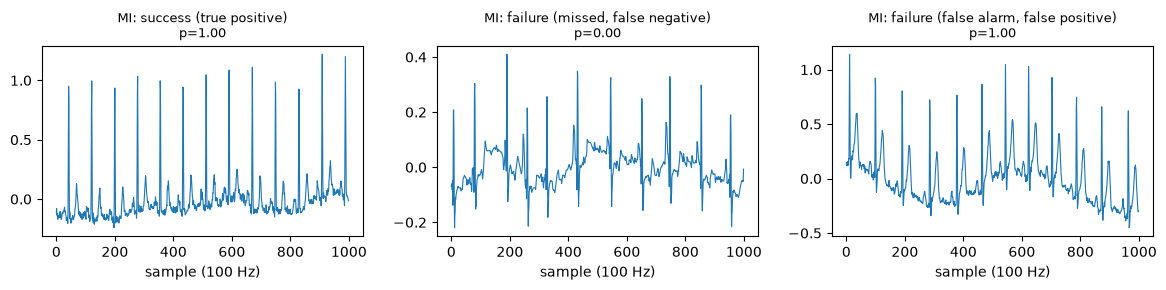

In [22]:
test_df = predictions["all"].query("split == 'test'").reset_index(drop=True)
id_to_row = {ecg_id: i for i, ecg_id in enumerate(df.index.values)}

def pick_examples(c, k=2):
    pos = test_df[test_df[f"y_{c}"] == 1]
    neg = test_df[test_df[f"y_{c}"] == 0]
    return {
        "success (true positive)": pos.nlargest(k, f"p_{c}"),
        "failure (missed, false negative)": pos.nsmallest(k, f"p_{c}"),
        "failure (false alarm, false positive)": neg.nlargest(k, f"p_{c}"),
    }

rows = []
for c in CLASSES:
    for kind, ex in pick_examples(c).items():
        for _, r in ex.iterrows():
            rows.append({"class": c, "case": kind, "ecg_id": r["ecg_id"],
                         "sex": r["sex"], "true": int(r[f"y_{c}"]),
                         "prob": round(r[f"p_{c}"], 3)})
examples_df = pd.DataFrame(rows)
display(examples_df)
examples_df.to_csv(os.path.join(RESULTS_DIR, "logreg_examples.csv"), index=False)

# Plot lead II for one success and one failure of a class
def plot_example(ecg_id, title):
    plt.plot(X[id_to_row[ecg_id], 1], linewidth=0.8)
    plt.title(title, fontsize=9)
    plt.xlabel("sample (100 Hz)")

c = "MI"
ex = pick_examples(c, k=1)
fig = plt.figure(figsize=(12, 3))
for i, (kind, d) in enumerate(ex.items()):
    plt.subplot(1, 3, i + 1)
    r = d.iloc[0]
    plot_example(r["ecg_id"], f"{c}: {kind}\np={r[f'p_{c}']:.2f}")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "logreg_examples_MI.png"), dpi=150)
plt.show()

### Save run configuration

In [ ]:
logreg_config = {
    "model": "logistic_regression (one-vs-rest, non-neural baseline)",
    "loss": "binary cross-entropy (log loss), L2 penalty, one classifier per class",
    "solver": "liblinear",
    "optimizer": "none (convex solver, no gradient training loop)",
    "feature_method": "mean of consecutive 10 samples per lead",
    "input_features": 1200,                                          
    "sampling_rate_hz": 100,
    "train_folds": [1, 2, 3, 4, 5, 6, 7],
    "val_folds": [8],
    "test_folds": [9, 10],
    "classes": CLASSES,
    "train_groups": TRAIN_GROUPS,
    "match_size": MATCH_SIZE,
    "C_values": C_VALUES,
    "selection_metric": "validation macro AUROC",
    "scaling": "StandardScaler fitted on training records only"
}

config_path = os.path.join(
    RESULTS_DIR, "logreg_config.json"
)

with open(config_path, "w") as f:
    json.dump(logreg_config, f, indent=2)

print("Saved:", config_path)

Saved: ../results/logreg_config.json
